# K562 allelic effect prediction: specific versus shared peaks

**K562 analysis for the TSS-based model project.** As clarified for this analysis,
the four existing prediction sets are used. The cis-Mamba checkpoint is **run 87,
K562 DNase pretraining**, epoch 15 (`val_loss=0.11846`), not a TSS-finetuned RNA
checkpoint. The model and input provenance are shown below.

This notebook evaluates **7,128 K562 v4 variants: 2,801 positives and 4,327 negatives**.
It adapts the peak-breadth method from `dsQTL_benchmark10.ipynb` to **K562 consensus
peaks**, using K562's own genome-wide median breadth. A separate contrast tests
variants in K562 peaks absent from the GM12878 annotation versus shared peaks.

The models are **cis-Mamba, AlphaGenome Atlas, Borzoi, and Enformer**, all using K562
DNase outputs. Predictions compare a single REF-to-ALT nucleotide substitution;
Mamba holds K562 accessibility context fixed and masks the same central 1 kb for
both alleles. Classification uses absolute predicted effects; signed effects use
ALT relative to REF. EpiBERT is not included.

All existing input rows and score definitions are preserved. FDR10 positives are
source statistical calls; v4 controls are the existing dosage-adjusted, low-effect
controls, not random genomic variants. Each subgroup therefore has its own chance
AP. This notebook reads saved scores and cached experimental peak calls, makes no
API requests, and runs no model inference. Tables and PNG/PDF figures are also saved
under the scoring run's `peak_stratification/` directory.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from IPython.display import display

BASE = Path('/data1/lesliec/sarthak/data/allelic_imbalance')
RUN = BASE / 'predictions/k562_v4_run87_20260922'
INPUT = BASE / 'k562_all_positives_expanded_v4/benchmark.tsv'
CACHE = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl/dsQTL_benchmark8_cache')
K562_PEAKS = BASE / 'k562_peak_cache/k562_merged.tsv.gz'
GM_PEAKS = CACHE / 'gm12878_merged.tsv.gz'
OUT = RUN / 'peak_stratification'
OUT.mkdir(exist_ok=True)
(OUT / 'figures').mkdir(exist_ok=True)
N_BOOT, SEED = 1000, 42
MODELS = {'cis-Mamba': 'mamba', 'AlphaGenome Atlas': 'atlas',
          'Borzoi': 'borzoi', 'Enformer': 'enformer'}
COLORS = {'cis-Mamba': '#2878B5', 'AlphaGenome Atlas': '#4C3B92',
          'Borzoi': '#55A868', 'Enformer': '#DD8452'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(2**20), b''):
            h.update(block)
    return h.hexdigest()

manifest = json.loads((RUN / 'manifest.json').read_text())
assert digest(INPUT) == manifest['input_sha256']
v = pd.read_csv(INPUT, sep='\t')
combined = pd.read_csv(RUN / 'comparison/scores_all_models.tsv', sep='\t')
assert len(v) == 7128 and v.label.sum() == 2801 and v.variant_id.is_unique
for column in ('variant_id', 'rsid', 'chrom', 'pos0', 'ref', 'alt', 'label'):
    np.testing.assert_array_equal(v[column], combined[column])
y = v.label.to_numpy(dtype=int)
native = pd.DataFrame({name: combined[f'{key}_primary_signed_score'].to_numpy()
                       for name, key in MODELS.items()}, index=v.variant_id)
central = pd.DataFrame({name: combined[f'{key}_near500bp_log2_alt_ref_pc1'].to_numpy()
                        for name, key in MODELS.items()}, index=v.variant_id)
assert np.isfinite(native.to_numpy()).all() and np.isfinite(central.to_numpy()).all()
print(f'Validated all {len(v):,} variants with complete support shared by all four models.')

run_metadata, provenance_rows = {}, []
for name, key in MODELS.items():
    info = json.loads((RUN / key / 'run.json').read_text())
    assert info['status'] == 'complete' and info['cell_type'] == 'K562'
    assert info['completed_variants'] == len(v)
    assert info.get('input_sha256', info.get('variants_sha256')) == manifest['input_sha256']
    saved = pd.read_csv(RUN / key / 'scores.tsv', sep='\t')
    for column in ('variant_id', 'rsid', 'ref', 'alt', 'label'):
        np.testing.assert_array_equal(saved[column], v[column])
    np.testing.assert_allclose(saved.primary_signed_score, native[name], rtol=1e-12, atol=1e-14)
    run_metadata[name] = info
    provenance_rows.append({'Model': name, 'Track / checkpoint':
        info.get('track', {}).get('index', info.get('ontology', info.get('checkpoint'))),
        'Assay': info['assay'], 'Variants': info['completed_variants']})
assert run_metadata['Enformer']['track']['index'] == 121
assert run_metadata['Borzoi']['track']['index'] == 1397
assert run_metadata['AlphaGenome Atlas']['ontology'] == 'EFO:0002067'
assert run_metadata['cis-Mamba']['checkpoint'].endswith('2025-07-18/00-23-52-538795/checkpoints/15-val_loss=0.11846.ckpt')
assert run_metadata['cis-Mamba']['data_path'].endswith('/K562_DNase.npz')
assert run_metadata['cis-Mamba']['mask_size'] == 1000
display(pd.DataFrame(provenance_rows).set_index('Model'))

Validated all 7,128 variants with complete support shared by all four models.


,Track / checkpoint,Assay,Variants
Model,,,
cis-Mamba,/data1/lesliec/sarthak/caduceus/outputs/2025-0...,DNase,7128
AlphaGenome Atlas,EFO:0002067,DNase,7128
Borzoi,1397,DNase,7128
Enformer,121,DNase,7128


## Scoring definitions

The primary analysis retains each run's original score. The sensitivity analysis
uses central **500 bp (Mamba), 501 bp (Atlas), or 512 bp (Borzoi/Enformer)** and
`log2((ALT sum + 1)/(REF sum + 1))`. The pseudocount is added after summation.
Atlas already supplies this native score; it is not given a second pseudocount.
The nearby window widths do not calibrate model output units or contexts.

In [2]:
definitions = pd.DataFrame([
    ['cis-Mamba', 500, 'log2(ALT mean / REF mean)', '0:500', 500],
    ['AlphaGenome Atlas', 501, 'log2((ALT sum+1)/(REF sum+1))', 'Atlas native', 501],
    ['Borzoi', 2048, 'log2(ALT sum / REF sum)', '3040:3104', 512],
    ['Enformer', 2048, 'log2(ALT sum / REF sum)', '440:456', 512],
], columns=['Model', 'Primary window bp', 'Primary signed effect', 'Primary bins', 'Sensitivity window bp'])
display(definitions.set_index('Model'))
windows = {'cis-Mamba': (0, 500, 0, 500), 'Borzoi': (3040, 3104, 3064, 3080),
           'Enformer': (440, 456, 446, 450)}
for name, (first, last, small_first, small_last) in windows.items():
    profile = np.load(RUN / MODELS[name] / 'predictions.npy', mmap_mode='r')
    axes = pd.read_csv(RUN / MODELS[name] / 'variants.tsv', sep='\t')
    np.testing.assert_array_equal(axes.variant_id, v.variant_id)
    assert profile.shape[0] == len(v) and profile.shape[2] == 2
    sums = profile[:, first:last, :].sum(axis=1, dtype=np.float64)
    assert np.isfinite(sums).all() and (sums > 0).all()
    np.testing.assert_allclose(np.log2(sums[:, 1]/sums[:, 0]), native[name], rtol=1e-9, atol=1e-12)
    small = profile[:, small_first:small_last, :].sum(axis=1, dtype=np.float64)
    np.testing.assert_allclose(np.log2((small[:, 1]+1)/(small[:, 0]+1)), central[name], rtol=1e-9, atol=1e-12)
np.testing.assert_allclose(native['AlphaGenome Atlas'], central['AlphaGenome Atlas'], rtol=0, atol=0)
print('Native and central scores reproduce the saved REF/ALT profiles; all allele axes and variant orders agree.')

,Primary window bp,Primary signed effect,Primary bins,Sensitivity window bp
Model,,,,
cis-Mamba,500,log2(ALT mean / REF mean),0:500,500
AlphaGenome Atlas,501,log2((ALT sum+1)/(REF sum+1)),Atlas native,501
Borzoi,2048,log2(ALT sum / REF sum),3040:3104,512
Enformer,2048,log2(ALT sum / REF sum),440:456,512


Native and central scores reproduce the saved REF/ALT profiles; all allele axes and variant orders agree.


## K562-specific versus generic peaks

The experimental DNase panel contains **674 tracks**, including four K562 tracks
(`121, 122, 123, 625`). As in the reference pipeline, its cached 128-bp calls use
track-specific approximate Poisson/BH thresholds at 0.01 on processed coverage.
A K562 consensus bin requires at least **2 of 4 tracks** (ceiling of 30%). Adjacent
consensus bins are merged. A panel track contributes to a merged peak's breadth
when at least **50% of the peak's bins** are called in that track.

The cutoff is the median across **all 278,763 K562 merged peaks**, independent of
variant labels and model scores: **197 tracks**. Relatively K562-specific peaks
have breadth ≤197; generic peaks have breadth >197. This differs from the GM12878
cutoff of 68. Breadth counts experimental tracks, including replicates, and does
not mean exclusive activity in K562. No thresholds are selected from model results.

The overlap calculation below recomputes K562 annotations from half-open hg38
intervals and checks them against every stored benchmark annotation. Variants
outside K562 peaks remain in the overall analysis and get a separate subgroup.

In [3]:
tracks = pd.read_csv(CACHE / 'tracks.tsv', sep='\t')
peak_provenance = json.loads((BASE / 'k562_peak_cache/provenance.json').read_text())
peaks = pd.read_csv(K562_PEAKS, sep='\t')
gm_peaks = pd.read_csv(GM_PEAKS, sep='\t')
k562_tracks = tracks.loc[tracks.description.eq('DNASE:K562'), 'index'].to_numpy(dtype=int)
assert len(tracks) == 674 and k562_tracks.tolist() == [121, 122, 123, 625]
assert peak_provenance['tracks'] == k562_tracks.tolist()
assert peak_provenance['fraction'] == .3 and peak_provenance['merged_fraction'] == .5
MEDIAN = float(peaks.breadth.median())
assert MEDIAN == peak_provenance['median'] == 197
assert len(peaks) == peak_provenance['peaks'] == 278763
assert peaks.median_breadth.eq(MEDIAN).all()
assert peaks.start.mod(128).eq(0).all() and peaks.end.mod(128).eq(0).all()
np.testing.assert_array_equal(peaks.n_bins, (peaks.end-peaks.start)//128)
np.testing.assert_array_equal(peaks.specificity,
    np.where(peaks.breadth <= MEDIAN, 'high_specificity', 'low_specificity'))

def overlap_annotation(variants, regions):
    result = pd.DataFrame({'peak_id': '', 'breadth': np.nan,
                           'specificity': 'outside'}, index=variants.index)
    for chrom, rows in variants.groupby('chrom'):
        p = regions.loc[regions.chrom.eq(chrom)].sort_values('start')
        if p.empty:
            continue
        starts, ends = p.start.to_numpy(), p.end.to_numpy()
        assert np.all(starts < ends) and np.all(starts[1:] >= ends[:-1])
        positions = rows.pos0.to_numpy(dtype=int)
        j = np.searchsorted(starts, positions, side='right') - 1
        hit = (j >= 0) & (positions < ends[np.maximum(j, 0)])
        rr, pp = rows.index.to_numpy()[hit], p.iloc[j[hit]]
        for column in result:
            result.loc[rr, column] = pp[column].to_numpy()
    return result

# Half-open boundary check: start is included, end excluded; adjacent peaks differ.
toy_peaks = pd.DataFrame({'chrom':['chr1','chr1'], 'start':[10,20], 'end':[20,30],
                         'peak_id':['first','second'], 'breadth':[1,2], 'specificity':['a','b']})
toy = pd.DataFrame({'chrom':['chr1']*5, 'pos0':[9,10,19,20,30]})
assert overlap_annotation(toy, toy_peaks).peak_id.tolist() == ['', 'first', 'first', 'second', '']
k562_annotation = overlap_annotation(v, peaks)
gm_annotation = overlap_annotation(v, gm_peaks)
category = k562_annotation.specificity.replace({'outside':'outside_K562_peaks'}).to_numpy()
np.testing.assert_array_equal(category, v.specificity)
np.testing.assert_array_equal(k562_annotation.peak_id, v.peak_id.fillna(''))
np.testing.assert_allclose(k562_annotation.breadth, v.peak_breadth, equal_nan=True)
in_k562 = category != 'outside_K562_peaks'
in_gm = gm_annotation.peak_id.ne('').to_numpy()
MASKS = {
    'Overall': np.ones(len(v), dtype=bool),
    'Generic K562 peaks': category == 'low_specificity',
    'Relatively K562-specific peaks': category == 'high_specificity',
    'Outside K562 peaks': ~in_k562,
    'All K562 peaks': in_k562,
    'K562 peaks absent from GM12878': in_k562 & ~in_gm,
    'K562 peaks shared with GM12878': in_k562 & in_gm,
    'K562-specific and absent from GM12878': (category == 'high_specificity') & ~in_gm,
}
assert sum(MASKS[g].astype(int) for g in list(MASKS)[1:4]).tolist() == [1]*len(v)
assert np.array_equal(MASKS['K562 peaks absent from GM12878'] | MASKS['K562 peaks shared with GM12878'], in_k562)
counts = pd.DataFrame([{'Subset': name, 'Variants': int(mask.sum()),
                       'Positives': int(y[mask].sum()), 'Negatives': int((1-y[mask]).sum()),
                       'Chance AP': float(y[mask].mean()) if mask.any() else np.nan}
                      for name, mask in MASKS.items()]).set_index('Subset')
display(counts.round(4))
counts.to_csv(OUT / 'subset_counts.tsv', sep='\t')

,Variants,Positives,Negatives,Chance AP
Subset,,,,
Overall,7128,2801,4327,0.3930
Generic K562 peaks,4643,2070,2573,0.4458
Relatively K562-specific peaks,2229,685,1544,0.3073
Outside K562 peaks,256,46,210,0.1797
All K562 peaks,6872,2755,4117,0.4009
K562 peaks absent from GM12878,2010,572,1438,0.2846
K562 peaks shared with GM12878,4862,2183,2679,0.4490
K562-specific and absent from GM12878,1475,425,1050,0.2881


## Peaks that differ from GM12878

The secondary contrast uses **the variant's 128-bp consensus-bin location**:
K562-peak variants outside the GM12878 consensus annotation versus variants inside
both annotations. It does not reuse GM12878 specificity labels. GM12878 consensus
requires ≥30% of its two panel tracks, i.e. at least one track. Therefore this is
presence/absence under the two existing consensus definitions, not a statistical
differential-accessibility test or proof of inactivity in all GM12878 experiments.
The stricter intersection, relatively K562-specific **and** absent from GM12878,
is also reported. Peak groups are assigned without consulting model predictions.

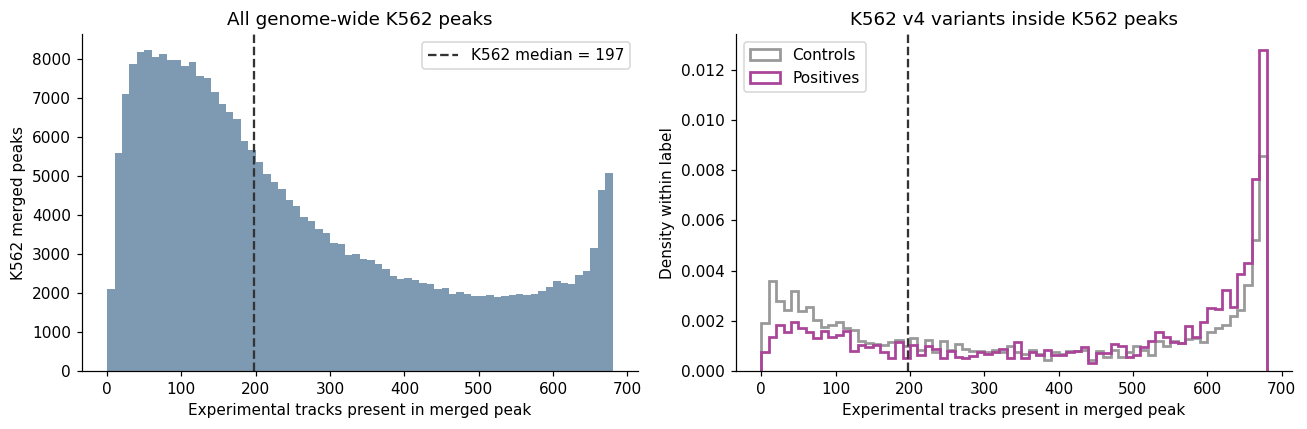

GM12878 overlap,Inside GM12878 peaks,Outside GM12878 peaks
K562 breadth category,,
high_specificity,754,1475
low_specificity,4108,535
outside_K562_peaks,57,199


In [4]:
def save_figure(fig, name):
    fig.savefig(OUT / 'figures' / f'{name}.png', dpi=180, bbox_inches='tight')
    fig.savefig(OUT / 'figures' / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
edges = np.arange(0, len(tracks)+11, 10)
axes[0].hist(peaks.breadth, bins=edges, color='#7E9AB3')
axes[0].axvline(MEDIAN, color='#333333', ls='--', label=f'K562 median = {MEDIAN:g}')
axes[0].set(xlabel='Experimental tracks present in merged peak', ylabel='K562 merged peaks',
            title='All genome-wide K562 peaks')
axes[0].legend()
for label, color, name in [(0, '#999999', 'Controls'), (1, '#AA4499', 'Positives')]:
    axes[1].hist(k562_annotation.breadth[(y==label)&in_k562], bins=edges, histtype='step',
                 density=True, lw=1.8, color=color, label=name)
axes[1].axvline(MEDIAN, color='#333333', ls='--')
axes[1].set(xlabel='Experimental tracks present in merged peak', ylabel='Density within label',
            title='K562 v4 variants inside K562 peaks')
axes[1].legend()
fig.tight_layout()
save_figure(fig, 'peak_breadth')
display(pd.crosstab(pd.Series(category, name='K562 breadth category'),
                   pd.Series(np.where(in_gm, 'Inside GM12878 peaks', 'Outside GM12878 peaks'), name='GM12878 overlap')))

## Classification and paired uncertainty

AP is `sklearn.metrics.average_precision_score` on **absolute effects**; AUROC is
also reported. Each subgroup keeps identical rows across all models. Subgroup
prevalence is the chance AP, so raw AP should be compared **between models within
a subgroup**, with the prevalence line shown in each panel.

Percentile 95% AP intervals use **1,000 paired bootstrap resamples of merged K562
peak clusters**, seed 42. Variants outside K562 peaks use chromosome/128-bp-bin
clusters. The same cluster draw is used across models and both score definitions.
Bootstrap weights resample complete clusters; the weighted AP calculation retains
score ties and is checked against scikit-learn. These intervals describe this
fixed benchmark; they do not incorporate model-training uncertainty.

In [5]:
SCORE_SETS = {'native_window': native, 'near500bp_pc1': central}
score_keys = [(definition, name) for definition in SCORE_SETS for name in MODELS]
score_matrix = np.column_stack([SCORE_SETS[d][name].abs().to_numpy() for d, name in score_keys])

def weighted_ap_many(labels, scores, weights):
    """AP for each row of nonnegative sample weights, with exact tied thresholds."""
    order = np.argsort(-scores, kind='mergesort')
    yy, ss, ww = labels[order], scores[order], weights[:, order]
    ends = np.r_[np.flatnonzero(np.diff(ss) != 0), len(ss)-1]
    tp = np.cumsum(ww * yy[None, :], axis=1)[:, ends]
    total = np.cumsum(ww, axis=1)[:, ends]
    precision = np.divide(tp, total, out=np.zeros_like(tp), where=total > 0)
    increments = np.diff(np.column_stack([np.zeros(len(ww)), tp]), axis=1)
    return np.sum(precision * increments, axis=1) / tp[:, -1]

toy_y = np.array([0, 1, 1, 0, 1, 0])
toy_s = np.array([.9, .9, .3, .3, .3, .1])
toy_w = np.array([[1,1,1,1,1,1], [0,2,1,0,3,1], [2,1,0,3,0,0]], dtype=float)
for test_scores in (toy_s, np.ones(6)):
    expected = [average_precision_score(toy_y, test_scores, sample_weight=w) for w in toy_w]
    np.testing.assert_allclose(weighted_ap_many(toy_y, test_scores, toy_w), expected, rtol=1e-12, atol=1e-14)

cluster = k562_annotation.peak_id.to_numpy().astype(str)
fallback = (v.chrom + ':' + (v.pos0//128).astype(str)).to_numpy()
cluster = np.where(cluster == '', fallback, cluster)
rng = np.random.default_rng(SEED)
rows, gaps, boot_arrays = [], [], {}
for group_index, (group, mask) in enumerate(MASKS.items()):
    idx = np.flatnonzero(mask)
    yy, ss = y[idx], score_matrix[idx]
    unique, inverse = np.unique(cluster[idx], return_inverse=True)
    point = np.array([average_precision_score(yy, ss[:,j]) for j in range(ss.shape[1])])
    auc = np.array([roc_auc_score(yy, ss[:,j]) for j in range(ss.shape[1])])
    np.testing.assert_allclose(weighted_ap_many(yy, ss[:,0], np.ones((1,len(yy)))), point[:1], atol=1e-12)
    boot = np.full((N_BOOT, len(score_keys)), np.nan)
    for start in range(0, N_BOOT, 32):
        n = min(32, N_BOOT-start)
        multiplicity = rng.multinomial(len(unique), np.ones(len(unique))/len(unique), size=n)
        weights = multiplicity[:, inverse].astype(float)
        valid = ((weights*yy).sum(axis=1)>0) & ((weights*(1-yy)).sum(axis=1)>0)
        for j in range(len(score_keys)):
            boot[start+np.flatnonzero(valid), j] = weighted_ap_many(yy, ss[:,j], weights[valid])
    for j, (definition, name) in enumerate(score_keys):
        good = np.isfinite(boot[:,j])
        low, high = np.percentile(boot[good,j], [2.5,97.5])
        rows.append(dict(subset=group, score=definition, model=name, n=len(idx), positives=int(yy.sum()),
            prevalence=float(yy.mean()), average_precision=point[j], auroc=auc[j],
            ap_minus_prevalence=point[j]-yy.mean(), ap_ci_low=low, ap_ci_high=high,
            clusters=len(unique), valid_bootstraps=int(good.sum())))
        if name != 'cis-Mamba':
            ours = score_keys.index((definition, 'cis-Mamba'))
            valid = np.isfinite(boot[:,j]) & np.isfinite(boot[:,ours])
            interval = np.percentile(boot[valid,ours]-boot[valid,j], [2.5,97.5])
            gaps.append(dict(subset=group, score=definition, reference='cis-Mamba', comparator=name,
                delta_ap=point[ours]-point[j], ci_low=interval[0], ci_high=interval[1],
                valid_bootstraps=int(valid.sum())))
    boot_arrays[f'group_{group_index}'] = boot
    print(f'{group}: n={len(idx):,}; {len(unique):,} clusters; {N_BOOT:,} paired draws complete', flush=True)

metrics = pd.DataFrame(rows)
paired = pd.DataFrame(gaps)
metrics.to_csv(OUT / 'stratified_metrics.tsv', sep='\t', index=False)
paired.to_csv(OUT / 'paired_model_differences.tsv', sep='\t', index=False)
np.savez_compressed(OUT / 'paired_bootstrap_ap.npz', **boot_arrays)
PRIMARY_GROUPS = ['Overall', 'Generic K562 peaks', 'Relatively K562-specific peaks']
DIFFERENTIAL_GROUPS = ['All K562 peaks', 'K562 peaks absent from GM12878', 'K562 peaks shared with GM12878']
def metric_table(definition, metric, groups=PRIMARY_GROUPS):
    return metrics[metrics.score.eq(definition)].pivot(index='model', columns='subset', values=metric).loc[list(MODELS), groups]
display(metric_table('native_window', 'average_precision').round(4))
display(metric_table('native_window', 'auroc').round(4))

Overall: n=7,128; 5,765 clusters; 1,000 paired draws complete


Generic K562 peaks: n=4,643; 3,686 clusters; 1,000 paired draws complete


Relatively K562-specific peaks: n=2,229; 1,830 clusters; 1,000 paired draws complete


Outside K562 peaks: n=256; 249 clusters; 1,000 paired draws complete


All K562 peaks: n=6,872; 5,516 clusters; 1,000 paired draws complete


K562 peaks absent from GM12878: n=2,010; 1,721 clusters; 1,000 paired draws complete


K562 peaks shared with GM12878: n=4,862; 3,942 clusters; 1,000 paired draws complete


K562-specific and absent from GM12878: n=1,475; 1,242 clusters; 1,000 paired draws complete


subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.4910,0.5216,0.4743
AlphaGenome Atlas,0.5164,0.5318,0.5494
Borzoi,0.5451,0.5632,0.5570
Enformer,0.5086,0.5317,0.5196


subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.5873,0.5727,0.6515
AlphaGenome Atlas,0.5928,0.5689,0.6991
Borzoi,0.6433,0.6214,0.7222
Enformer,0.6075,0.5897,0.6940


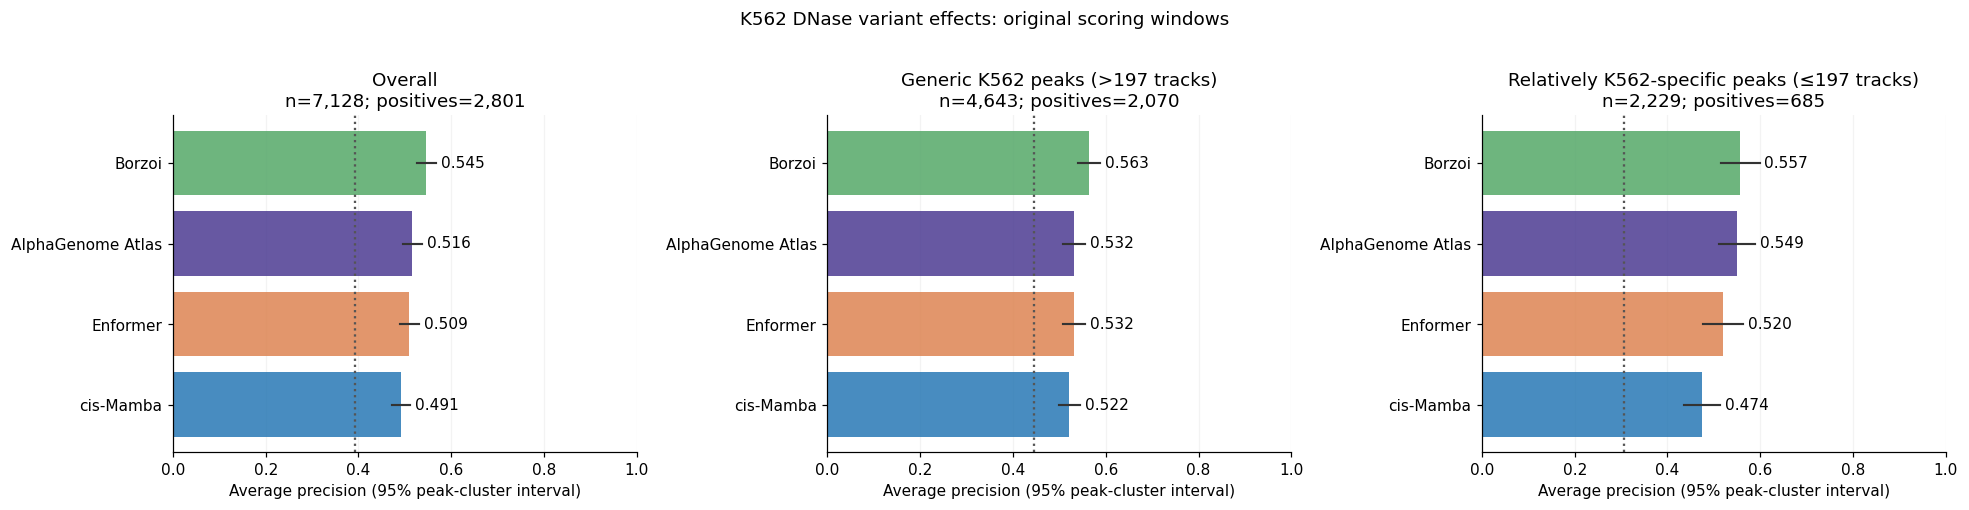

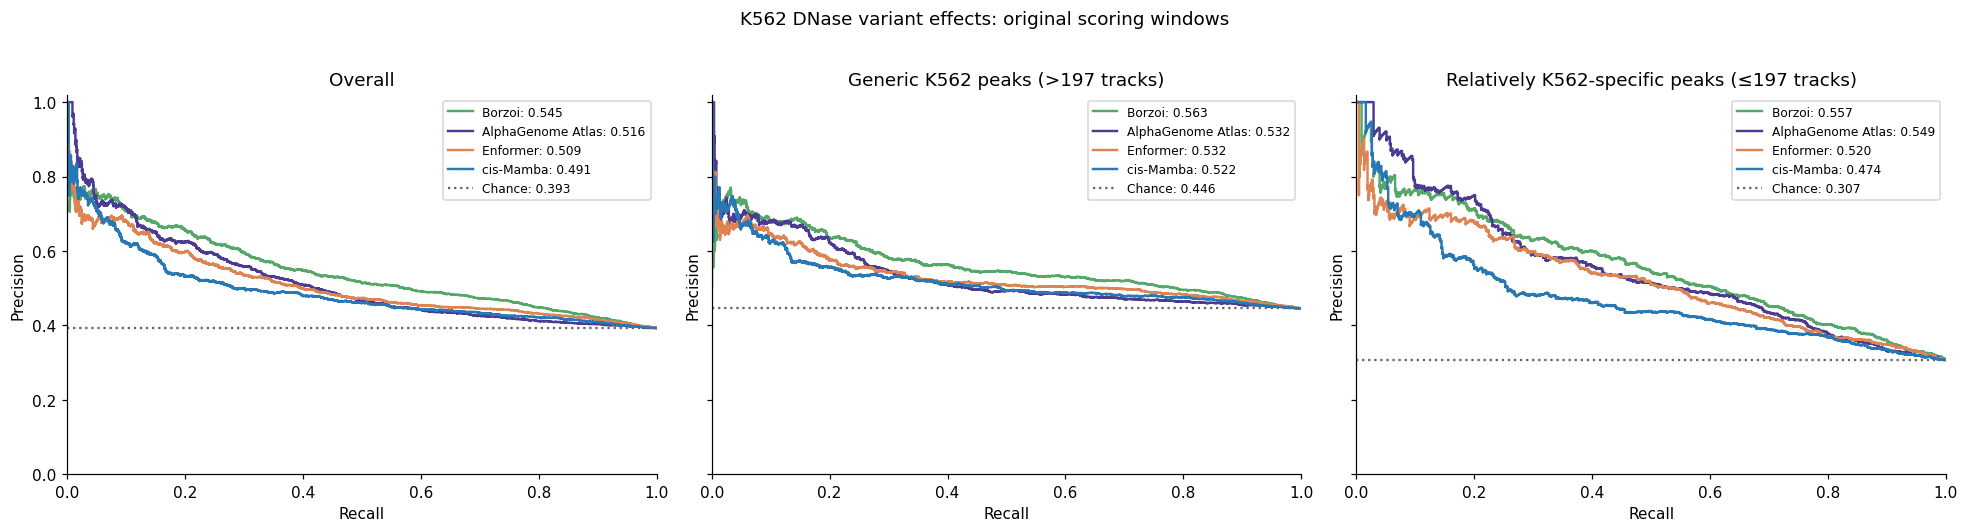

In [6]:
order = metric_table('native_window', 'average_precision').sort_values('Overall', ascending=False).index.tolist()
SHORT = {'Overall': 'Overall', 'Generic K562 peaks': 'Generic K562 peaks (>197 tracks)',
         'Relatively K562-specific peaks': 'Relatively K562-specific peaks (≤197 tracks)',
         'All K562 peaks': 'All K562-peak variants',
         'K562 peaks absent from GM12878': 'K562 peaks absent from GM12878',
         'K562 peaks shared with GM12878': 'K562 peaks shared with GM12878'}

def comparison_bars(definition, groups, filename, title):
    fig, axes = plt.subplots(1, len(groups), figsize=(6*len(groups), 4.5), sharex=True)
    for ax, group in zip(np.atleast_1d(axes), groups):
        d = metrics[metrics.score.eq(definition) & metrics.subset.eq(group)].set_index('model').loc[order]
        vals = d.average_precision.to_numpy()
        ax.barh(np.arange(len(order)), vals, color=[COLORS[name] for name in order], alpha=.85)
        for j, row in enumerate(d.itertuples()):
            ax.plot([row.ap_ci_low, row.ap_ci_high], [j,j], color='#333333', lw=1.4)
            ax.text(row.ap_ci_high+.01, j, f'{row.average_precision:.3f}', va='center')
        ax.axvline(counts.loc[group, 'Chance AP'], color='#555555', ls=':', label='Chance AP')
        ax.set_yticks(np.arange(len(order)), order)
        ax.invert_yaxis()
        ax.set(xlim=(0,1), xlabel='Average precision (95% peak-cluster interval)',
               title=f'{SHORT[group]}\nn={int(counts.loc[group,"Variants"]):,}; positives={int(counts.loc[group,"Positives"]):,}')
        ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    save_figure(fig, filename)

def pr_curves(definition, groups, filename, title):
    fig, axes = plt.subplots(1, len(groups), figsize=(6*len(groups), 4.7), sharex=True, sharey=True)
    for ax, group in zip(np.atleast_1d(axes), groups):
        mask = MASKS[group]
        for name in order:
            score = SCORE_SETS[definition][name].abs().to_numpy()[mask]
            precision, recall, _ = precision_recall_curve(y[mask], score)
            ap = average_precision_score(y[mask], score)
            ax.step(recall, precision, where='post', lw=1.6, color=COLORS[name], label=f'{name}: {ap:.3f}')
        ax.axhline(y[mask].mean(), color='#666666', ls=':', label=f'Chance: {y[mask].mean():.3f}')
        ax.set(xlim=(0,1), ylim=(0,1.02), xlabel='Recall', ylabel='Precision', title=SHORT[group])
        ax.legend(fontsize=8, loc='upper right')
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    save_figure(fig, filename)

comparison_bars('native_window', PRIMARY_GROUPS, 'native_peak_specificity_ap', 'K562 DNase variant effects: original scoring windows')
pr_curves('native_window', PRIMARY_GROUPS, 'native_peak_specificity_pr', 'K562 DNase variant effects: original scoring windows')

## K562 peaks absent from GM12878 versus shared peaks

These panels use the same completed K562 predictions. Only the experimental
peak-overlap grouping changes. No GM12878 model outputs enter this comparison.

,Variants,Positives,Negatives,Chance AP
Subset,,,,
All K562 peaks,6872,2755,4117,0.4009
K562 peaks absent from GM12878,2010,572,1438,0.2846
K562 peaks shared with GM12878,4862,2183,2679,0.4490


subset,All K562 peaks,K562 peaks absent from GM12878,K562 peaks shared with GM12878
model,,,
cis-Mamba,0.4939,0.4624,0.5225
AlphaGenome Atlas,0.5190,0.5498,0.5337
Borzoi,0.5465,0.5473,0.5671
Enformer,0.5117,0.5100,0.5344


subset,All K562 peaks,K562 peaks absent from GM12878,K562 peaks shared with GM12878
model,,,
cis-Mamba,0.5830,0.6732,0.5657
AlphaGenome Atlas,0.5886,0.7257,0.5649
Borzoi,0.6378,0.7281,0.6208
Enformer,0.6033,0.7146,0.5848


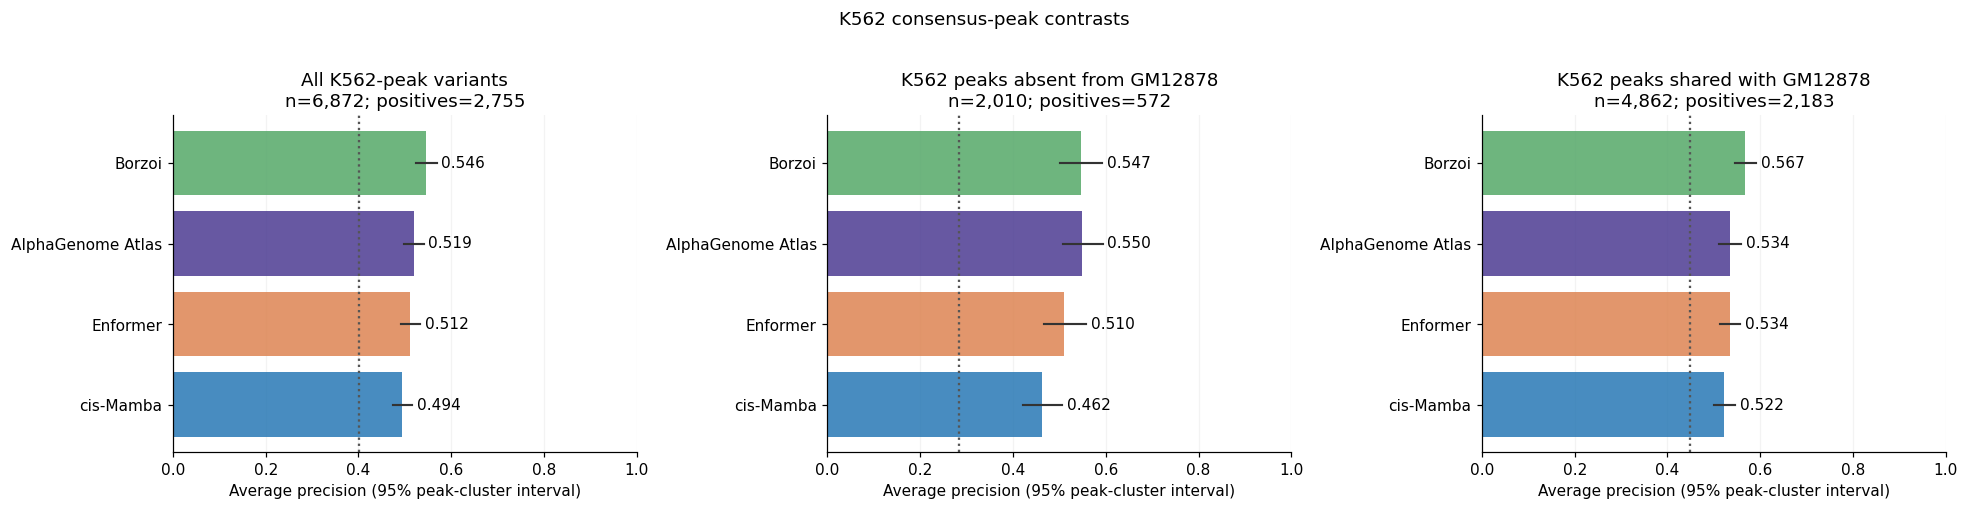

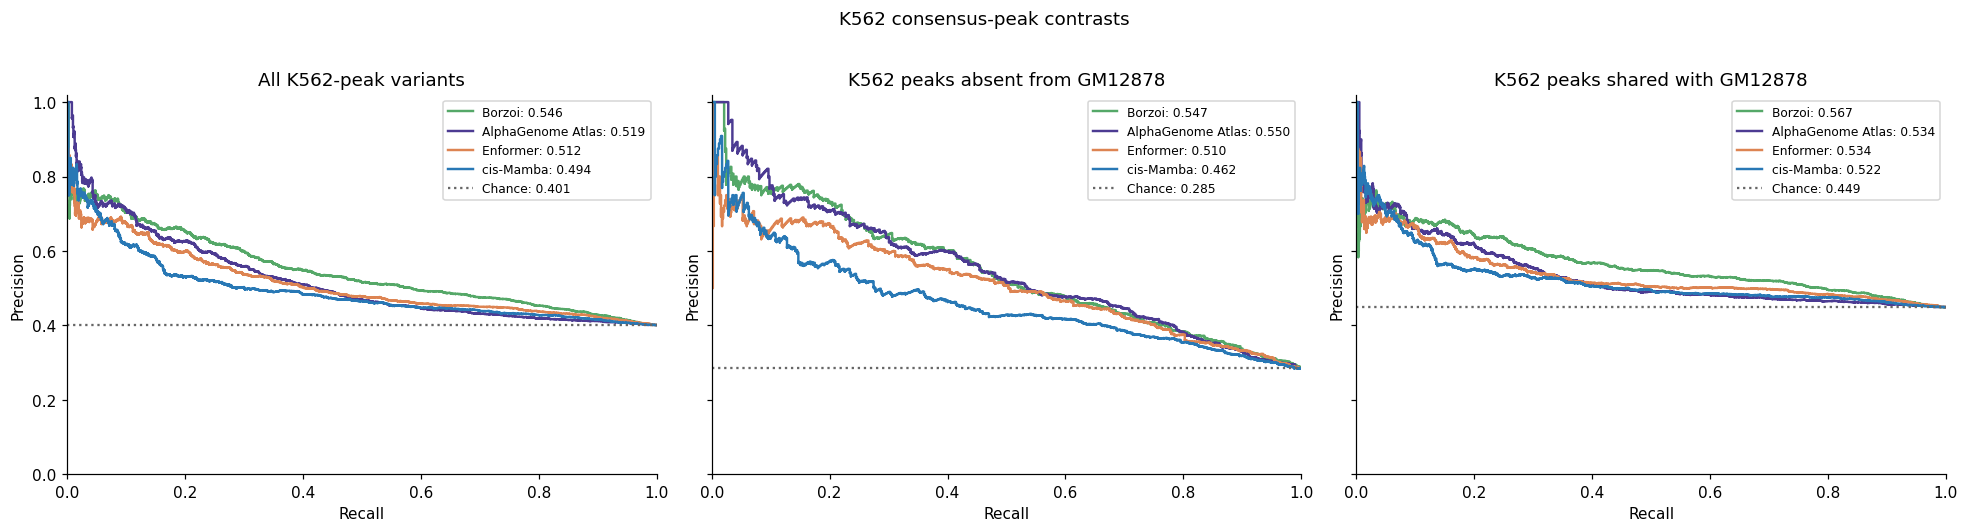

,n,positives,prevalence,average_precision,ap_ci_low,ap_ci_high,auroc
model,,,,,,,
cis-Mamba,1475,425,0.2881,0.4537,0.4081,0.5080,0.6524
AlphaGenome Atlas,1475,425,0.2881,0.5407,0.4870,0.5903,0.7098
Borzoi,1475,425,0.2881,0.5419,0.4885,0.5923,0.7175
Enformer,1475,425,0.2881,0.5021,0.4504,0.5552,0.6990


In [7]:
display(counts.loc[DIFFERENTIAL_GROUPS].round(4))
display(metric_table('native_window', 'average_precision', DIFFERENTIAL_GROUPS).round(4))
display(metric_table('native_window', 'auroc', DIFFERENTIAL_GROUPS).round(4))
comparison_bars('native_window', DIFFERENTIAL_GROUPS, 'native_k562_vs_gm12878_ap', 'K562 consensus-peak contrasts')
pr_curves('native_window', DIFFERENTIAL_GROUPS, 'native_k562_vs_gm12878_pr', 'K562 consensus-peak contrasts')
strict = metrics[metrics.subset.eq('K562-specific and absent from GM12878') & metrics.score.eq('native_window')]
display(strict[['model','n','positives','prevalence','average_precision','ap_ci_low','ap_ci_high','auroc']].set_index('model').round(4))

## Scoring-window sensitivity

This is a predeclared sensitivity view using the already saved 500–512-bp scores
and a pseudocount of one. It does not replace the original primary scores based
on which gives better results. Atlas has the same score in both views.

subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.4916,0.5222,0.4747
AlphaGenome Atlas,0.5164,0.5318,0.5494
Borzoi,0.5380,0.5485,0.5560
Enformer,0.5198,0.5378,0.5270


subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.5879,0.5732,0.6519
AlphaGenome Atlas,0.5928,0.5689,0.6991
Borzoi,0.6227,0.5875,0.7096
Enformer,0.6065,0.5796,0.6816


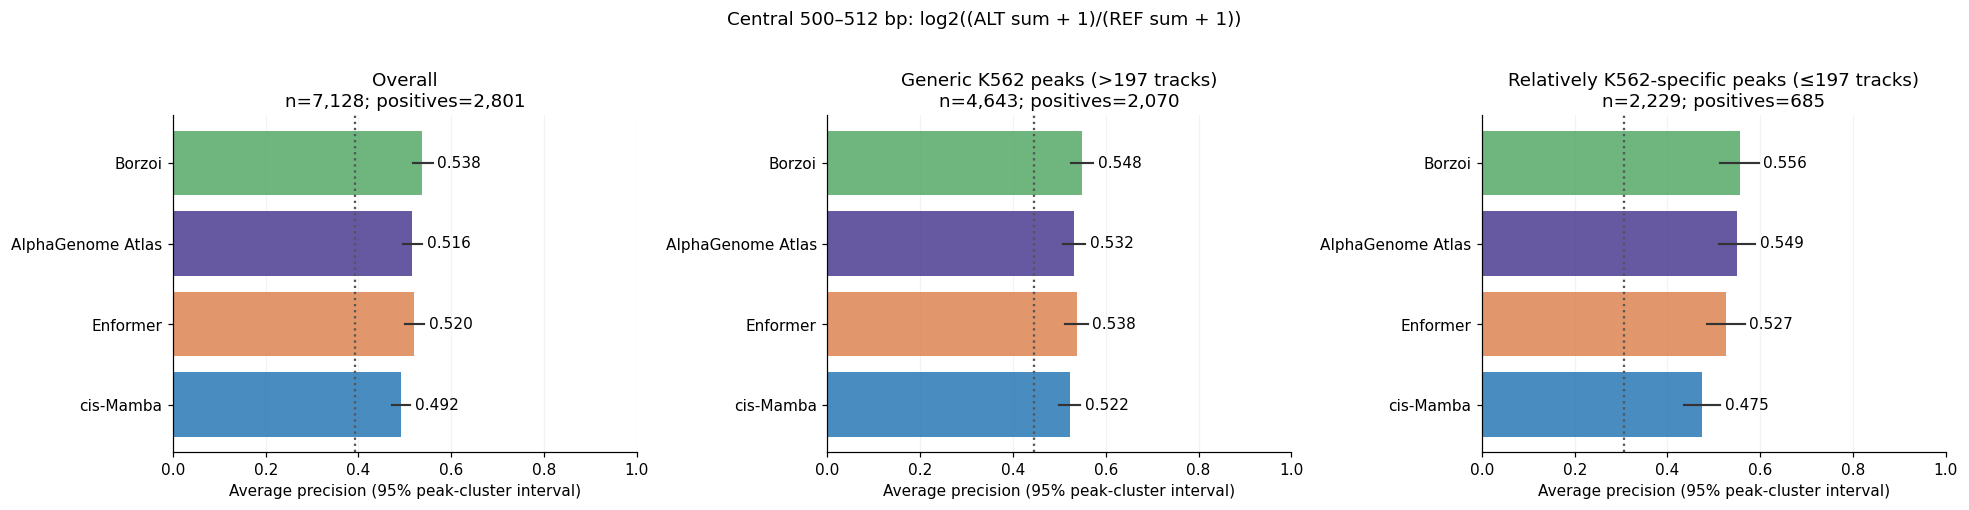

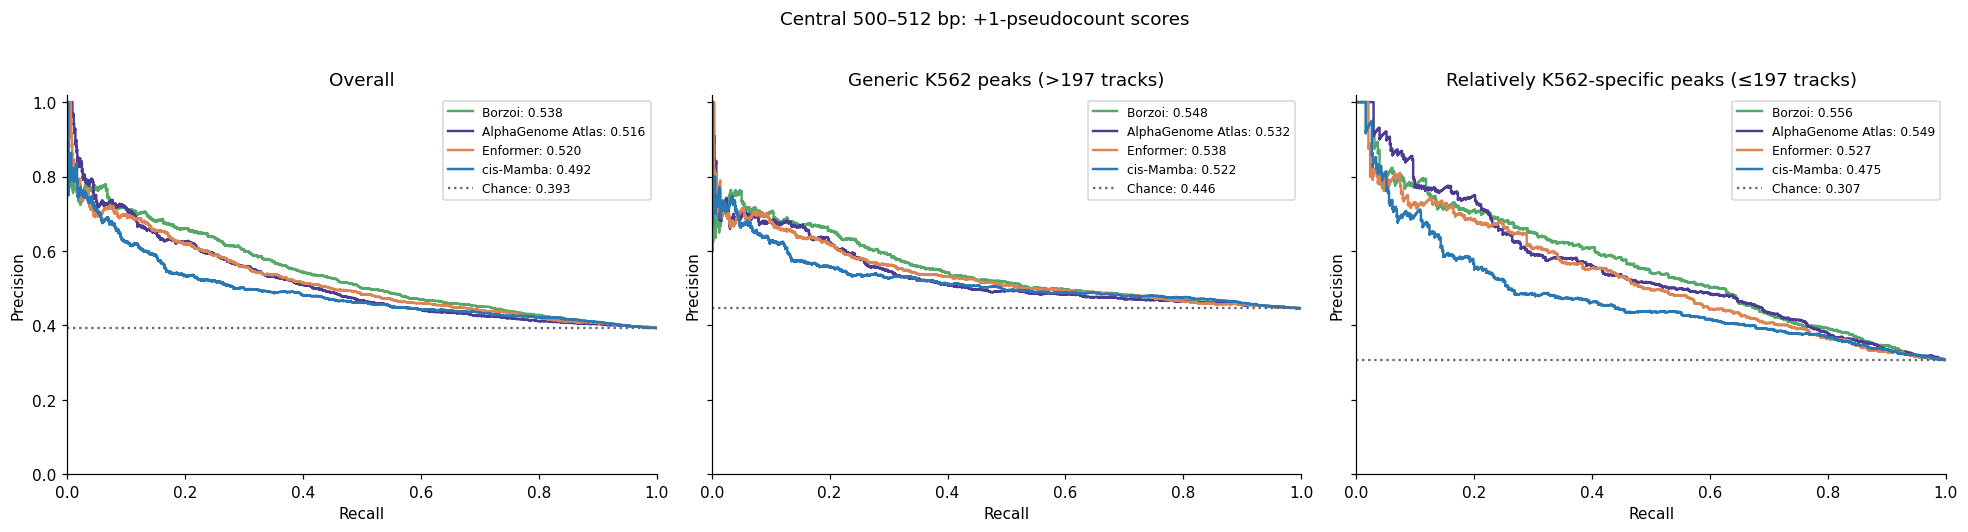

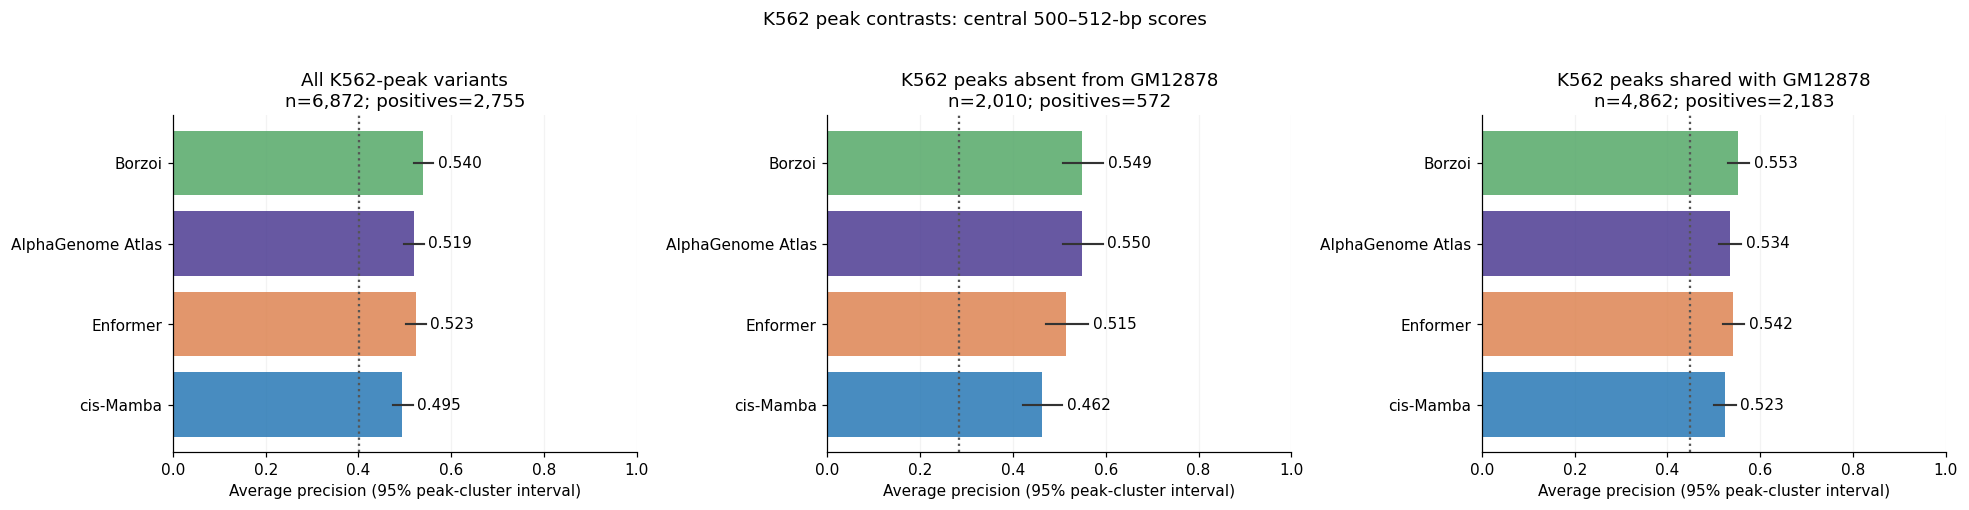

Change in AP: approximately 500-bp score minus original score


subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.0005,0.0006,0.0004
AlphaGenome Atlas,0.0000,0.0000,0.0000
Borzoi,-0.0071,-0.0147,-0.0010
Enformer,0.0111,0.0061,0.0074


In [8]:
display(metric_table('near500bp_pc1', 'average_precision').round(4))
display(metric_table('near500bp_pc1', 'auroc').round(4))
comparison_bars('near500bp_pc1', PRIMARY_GROUPS, 'central_peak_specificity_ap', 'Central 500–512 bp: log2((ALT sum + 1)/(REF sum + 1))')
pr_curves('near500bp_pc1', PRIMARY_GROUPS, 'central_peak_specificity_pr', 'Central 500–512 bp: +1-pseudocount scores')
comparison_bars('near500bp_pc1', DIFFERENTIAL_GROUPS, 'central_k562_vs_gm12878_ap', 'K562 peak contrasts: central 500–512-bp scores')
print('Change in AP: approximately 500-bp score minus original score')
display((metric_table('near500bp_pc1','average_precision')-metric_table('native_window','average_precision')).round(4))

## Paired model differences

Positive differences favor cis-Mamba; negative differences favor the comparator.
Both models use the same bootstrap cluster multiplicities and the same variants.
The displayed intervals are unadjusted descriptive intervals for this fixed
benchmark, not a test of all possible model and subgroup comparisons.

,subset,comparator,delta_ap,ci_low,ci_high,valid_bootstraps
0,Overall,AlphaGenome Atlas,-0.0254,-0.0378,-0.0136,1000
1,Overall,Borzoi,-0.0541,-0.0704,-0.0390,1000
2,Overall,Enformer,-0.0176,-0.0325,-0.0030,1000
6,Generic K562 peaks,AlphaGenome Atlas,-0.0102,-0.0225,0.0037,1000
7,Generic K562 peaks,Borzoi,-0.0416,-0.0583,-0.0249,1000
8,Generic K562 peaks,Enformer,-0.0101,-0.0256,0.0060,1000
12,Relatively K562-specific peaks,AlphaGenome Atlas,-0.0751,-0.1011,-0.0509,1000
13,Relatively K562-specific peaks,Borzoi,-0.0827,-0.1163,-0.0473,1000
14,Relatively K562-specific peaks,Enformer,-0.0453,-0.0762,-0.0165,1000
30,K562 peaks absent from GM12878,AlphaGenome Atlas,-0.0874,-0.1168,-0.0578,1000


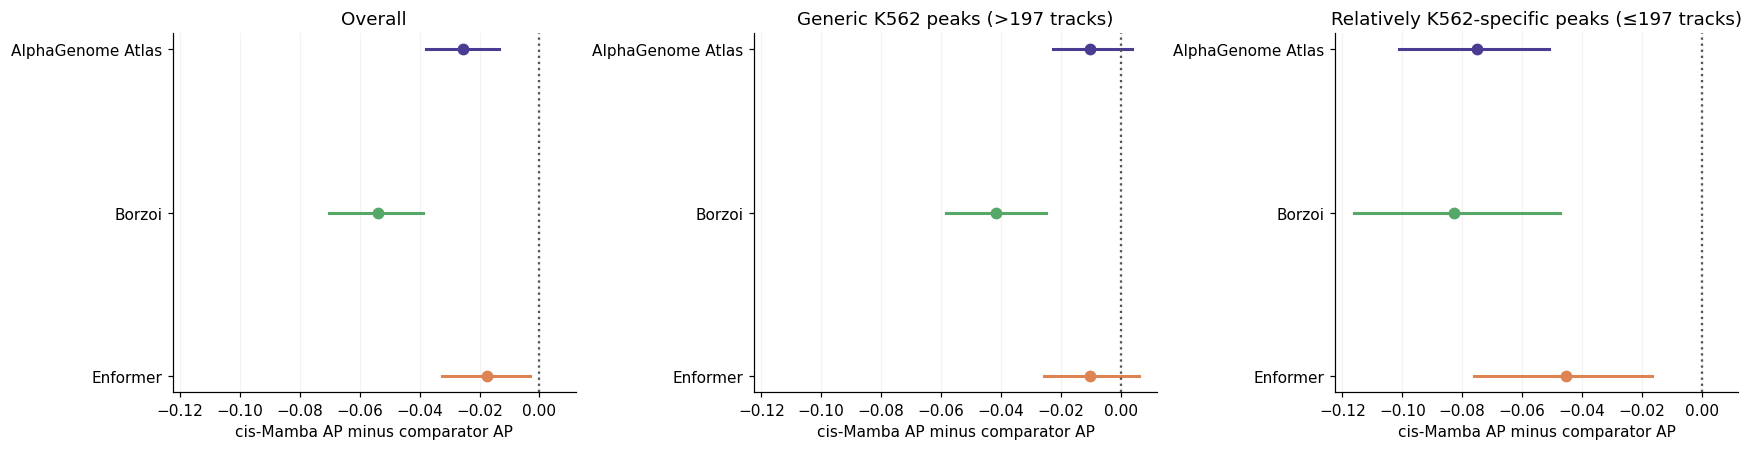

In [9]:
display(paired[paired.score.eq('native_window') & paired.subset.isin(PRIMARY_GROUPS+DIFFERENTIAL_GROUPS[1:])]
        [['subset','comparator','delta_ap','ci_low','ci_high','valid_bootstraps']].round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True)
comparators = [name for name in MODELS if name != 'cis-Mamba']
for ax, group in zip(axes, PRIMARY_GROUPS):
    d = paired[paired.score.eq('native_window') & paired.subset.eq(group)].set_index('comparator').loc[comparators]
    for j, row in enumerate(d.itertuples()):
        ax.plot([row.ci_low, row.ci_high], [j,j], color=COLORS[row.Index], lw=2)
        ax.scatter([row.delta_ap], [j], color=COLORS[row.Index], s=45)
    ax.axvline(0, color='#555555', ls=':')
    ax.set_yticks(range(len(comparators)), comparators)
    ax.invert_yaxis()
    ax.set(xlabel='cis-Mamba AP minus comparator AP', title=SHORT[group])
    ax.grid(axis='x', alpha=.15)
fig.tight_layout()
save_figure(fig, 'paired_native_ap_differences')

## Signed effect direction and correlation

Observed effects use the v4 field **`observed_dosage_adjusted_log2_alt_ref`**;
positive values favor ALT, matching every model score. The observed dosage
adjustment is inherited from the benchmark and is not re-estimated from model
outputs. Pearson and Spearman correlations are shown for positives, controls,
and the combined cohort separately; balanced controls can otherwise dominate the
combined distribution. Direction accuracy excludes exactly zero observed or
predicted effects and reports its own denominator. Plots use positives only and
color points by K562 peak category.

Positives only: pearson_r


subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.3130,0.2911,0.3741
AlphaGenome Atlas,0.4002,0.3688,0.4428
Borzoi,0.2730,0.2590,0.2868
Enformer,0.3030,0.2852,0.3411


Positives only: spearman_r


subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.4009,0.3564,0.4783
AlphaGenome Atlas,0.4802,0.4338,0.5514
Borzoi,0.4124,0.3708,0.4578
Enformer,0.3842,0.3516,0.4417


Positives only: direction_accuracy


subset,Overall,Generic K562 peaks,Relatively K562-specific peaks
model,,,
cis-Mamba,0.6339,0.6120,0.6935
AlphaGenome Atlas,0.6523,0.6324,0.7038
Borzoi,0.6375,0.6164,0.6965
Enformer,0.6196,0.6018,0.6686


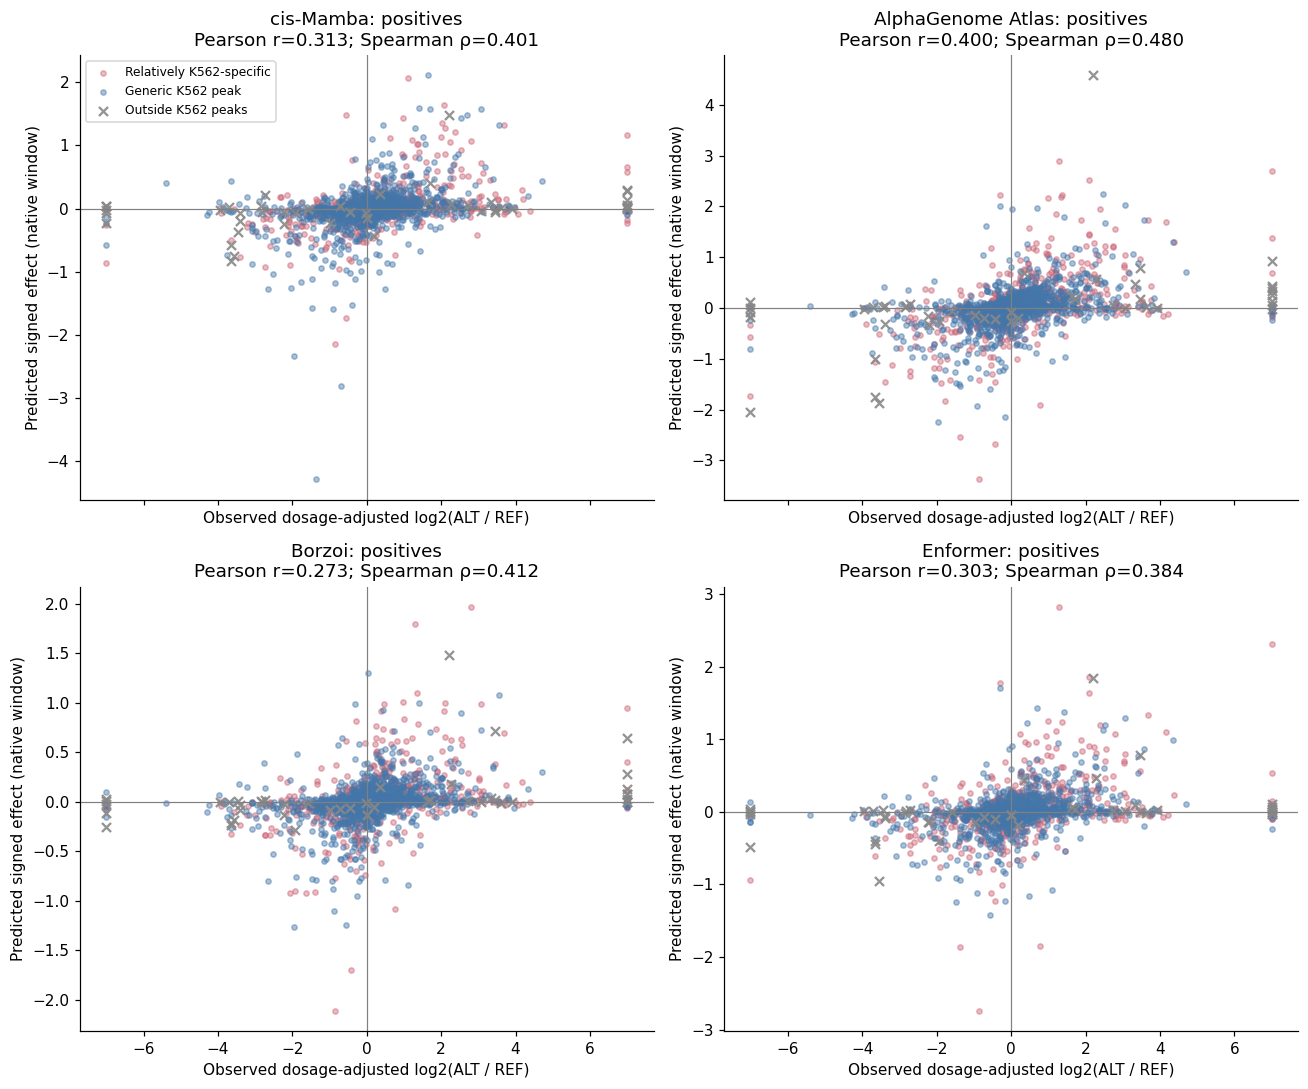

In [10]:
observed = v.observed_dosage_adjusted_log2_alt_ref.to_numpy(dtype=float)
correlations = []
for definition, signed in SCORE_SETS.items():
    for group, group_mask in MASKS.items():
        for population, population_mask in [('Combined', np.ones(len(v),bool)), ('Positives', y==1), ('Controls',y==0)]:
            for name in MODELS:
                predicted = signed[name].to_numpy()
                mask = group_mask & population_mask & np.isfinite(observed) & np.isfinite(predicted)
                can_correlate = mask.sum() >= 3 and np.ptp(observed[mask])>0 and np.ptp(predicted[mask])>0
                direction = mask & (observed != 0) & (predicted != 0)
                correlations.append(dict(subset=group, score=definition, population=population, model=name,
                    n=int(mask.sum()), pearson_r=float(pearsonr(observed[mask],predicted[mask]).statistic) if can_correlate else np.nan,
                    spearman_r=float(spearmanr(observed[mask],predicted[mask]).statistic) if can_correlate else np.nan,
                    direction_n=int(direction.sum()), direction_accuracy=float(np.mean(np.sign(observed[direction])==np.sign(predicted[direction]))) if direction.any() else np.nan))
correlations = pd.DataFrame(correlations)
correlations.to_csv(OUT / 'signed_effect_metrics.tsv', sep='\t', index=False)
positive_metrics = correlations[correlations.score.eq('native_window') & correlations.population.eq('Positives')]
for metric in ('pearson_r','spearman_r','direction_accuracy'):
    print(f'Positives only: {metric}')
    display(positive_metrics.pivot(index='model',columns='subset',values=metric).loc[list(MODELS),PRIMARY_GROUPS].round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True)
category_colors = {'high_specificity':'#CC6677', 'low_specificity':'#4477AA', 'outside_K562_peaks':'#888888'}
category_names = {'high_specificity':'Relatively K562-specific', 'low_specificity':'Generic K562 peak', 'outside_K562_peaks':'Outside K562 peaks'}
for ax, name in zip(axes.flat, MODELS):
    predicted = native[name].to_numpy()
    for cat in category_colors:
        mask = (y==1)&(category==cat)&np.isfinite(observed)
        ax.scatter(observed[mask], predicted[mask], s=12 if cat!='outside_K562_peaks' else 35,
                   marker='o' if cat!='outside_K562_peaks' else 'x', alpha=.45 if cat!='outside_K562_peaks' else .9,
                   color=category_colors[cat], label=category_names[cat], rasterized=True)
    row = positive_metrics[positive_metrics.subset.eq('Overall') & positive_metrics.model.eq(name)].iloc[0]
    ax.axhline(0,color='gray',lw=.8);ax.axvline(0,color='gray',lw=.8)
    ax.set(title=f'{name}: positives\nPearson r={row.pearson_r:.3f}; Spearman ρ={row.spearman_r:.3f}',
           xlabel='Observed dosage-adjusted log2(ALT / REF)', ylabel='Predicted signed effect (native window)')
axes[0,0].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, 'positive_signed_effects')

## Row-level exports and provenance

The stratified export retains all source annotations and adds independently
recomputed K562/GM12878 overlap fields, each subgroup membership, and signed and
absolute scores. Source input files, model predictions, and the GM12878 reference
notebook are left unchanged. These analyses stratify K562 effects by experimental
peak context; they do not measure paired allele effects in two cell types.

In [11]:
export = combined.copy()
export['k562_peak_id_checked'] = k562_annotation.peak_id
export['k562_peak_breadth_checked'] = k562_annotation.breadth
export['k562_specificity_checked'] = category
export['gm12878_peak_id'] = gm_annotation.peak_id
export['in_gm12878_consensus_peak'] = in_gm
group_columns = {}
for number, (group, mask) in enumerate(MASKS.items()):
    column = f'subset_{number}'
    export[column] = mask
    group_columns[column] = group
export['bootstrap_cluster'] = cluster
export.to_csv(OUT / 'variant_scores_and_peak_strata.tsv.gz', sep='\t', index=False)
definitions.to_csv(OUT / 'score_definitions.tsv', sep='\t', index=False)
source_files = [INPUT, RUN/'comparison/scores_all_models.tsv', K562_PEAKS, GM_PEAKS,
                BASE/'k562_peak_cache/provenance.json', CACHE/'tracks.tsv', CACHE/'track_thresholds.tsv', CACHE/'peaks.done.json']
provenance = dict(status='complete', cell_type='K562', mamba_run=87,
    mamba_model_type='DNase pretraining; no TSS-finetuned RNA checkpoint evaluated',
    variants=len(v), positives=int(y.sum()), common_variants=len(v), input_sha256=digest(INPUT),
    primary_peak_definition='K562 consensus merged peaks; breadth <= genome-wide K562 median is relatively specific',
    track_panel_size=len(tracks), k562_track_indices=k562_tracks.tolist(), k562_peak_count=len(peaks),
    median_breadth=MEDIAN, k562_consensus_required_tracks=2, merged_track_presence_fraction=.5,
    differential_definition='Variant overlaps K562 consensus peak and is absent from/present in GM12878 consensus peak',
    subgroup_columns=group_columns, bootstrap=dict(draws=N_BOOT,seed=SEED,unit='merged K562 peak; outside fallback chromosome/128-bp bin',score_columns=score_keys,groups=list(MASKS)),
    sources=[dict(path=str(p),sha256=digest(p)) for p in source_files],
    run_metadata=run_metadata, new_inference=False, api_requests=0)
(OUT / 'provenance.json').write_text(json.dumps(provenance,indent=2)+'\n')
primary = metric_table('native_window','average_precision')
lines = ['K562 allelic-effect peak stratification', '',
         f'Complete: {len(v):,} variants scored by all four models. K562 median peak breadth: {MEDIAN:g}/674 experimental tracks.', '',
         '| Model | Overall AP | Generic K562 AP | Relatively K562-specific AP |', '|---|---:|---:|---:|']
for name in order:
    a = primary.loc[name]
    lines.append(f'| {name} | {a.iloc[0]:.4f} | {a.iloc[1]:.4f} | {a.iloc[2]:.4f} |')
lines += ['', 'Each subgroup has its own positive prevalence; see subset_counts.tsv. The notebook includes paired cluster-bootstrap intervals, K562-versus-GM12878 peak contrasts, scoring-window sensitivity, and signed effect metrics.', '',
          'Mamba is K562 DNase pretraining run 87, epoch 15, val_loss=0.11846. All predictions are existing accessibility outputs; no TSS-finetuned RNA model is evaluated.', '',
          'Notebook: /data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl/allelic_effect_prediction_k562.ipynb']
(OUT / 'README.md').write_text('\n'.join(lines)+'\n')
print(f'COMPLETE: {len(v):,} variants; {len(MODELS)} models; {len(MASKS)} subsets; {N_BOOT:,} paired bootstrap draws per subset.')
print(f'Tables and standalone figures: {OUT}')

COMPLETE: 7,128 variants; 4 models; 8 subsets; 1,000 paired bootstrap draws per subset.
Tables and standalone figures: /data1/lesliec/sarthak/data/allelic_imbalance/predictions/k562_v4_run87_20260922/peak_stratification
